In [2]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as f

from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [3]:
from pathlib import Path

# Kaggle mein outputs save karne ke liye working directory use hoti hai
PROJECT_ROOT = Path("/kaggle/working/PaddyVision-AI") 
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

# Kaggle dataset ka default path (right panel mein aapne 'riceUAS' add kiya hai)
UAV_DIR = Path("/kaggle/input/datasets/adnanmusheer/riceuas") 
# Note: Agar 'riceuas' folder not found error de, to ek baar "/kaggle/input/riceUAS" try karke dekhna

print("Dataset exists:", UAV_DIR.exists())
print("Dataset path:", UAV_DIR)

Dataset exists: True
Dataset path: /kaggle/input/datasets/adnanmusheer/riceuas


In [4]:
print("UAV directory:", UAV_DIR)

print("\nTop-level contents:")
for item in UAV_DIR.iterdir():
    print(item.name)

UAV directory: /kaggle/input/datasets/adnanmusheer/riceuas

Top-level contents:
riceUAS


In [5]:
UAV_DATA_DIR = UAV_DIR / "riceUAS"

print("Dataset root:", UAV_DATA_DIR)
print("Exists:", UAV_DATA_DIR.exists())

print("\nContents:")
for item in UAV_DATA_DIR.iterdir():
    print(item.name)

Dataset root: /kaggle/input/datasets/adnanmusheer/riceuas/riceUAS
Exists: True

Contents:
README_management.txt
Images
Agronomic
README_variables.txt


In [6]:
AGRONOMIC_DIR = UAV_DATA_DIR / "Agronomic"

print("Agronomic path:", AGRONOMIC_DIR)
print("Exists:", AGRONOMIC_DIR.exists())

print("\nContents:")
for item in AGRONOMIC_DIR.iterdir():
    print(item.name)

Agronomic path: /kaggle/input/datasets/adnanmusheer/riceuas/riceUAS/Agronomic
Exists: True

Contents:
2022
2021


In [7]:
YEAR_2021_DIR = AGRONOMIC_DIR / "2021"

print("2021 contents:")

for item in YEAR_2021_DIR.iterdir():
    print(item.name)

2021 contents:
constant_agronomic_traits_2021.csv


In [8]:
yield_2021_path = YEAR_2021_DIR / "constant_agronomic_traits_2021.csv"

agronomic_2021 = pd.read_csv(yield_2021_path)

print("Shape:", agronomic_2021.shape)
print("\nColumns:")
print(agronomic_2021.columns.tolist())

print("\nFirst 5 rows:")
display(agronomic_2021.head())

Shape: (252, 13)

Columns:
['Plot_Number', 'Rice_Cultivar', 'Experiment_Name', 'Plot_Center', 'Seeding_Rate', 'Nitrogen_Rate', 'Replicate', 'Yield', 'Emergence_Date_DOY', 'Heading_25', 'Heading_50', 'Heading_100', 'Final_Lodge']

First 5 rows:


,Plot_Number,Rice_Cultivar,Experiment_Name,Plot_Center,Seeding_Rate,Nitrogen_Rate,Replicate,Yield,Emergence_Date_DOY,Heading_25,Heading_50,Heading_100,Final_Lodge
0,33761,IAC600,Tiara,"9' 9""""",112.0,75,1,6.002350,140,NaN,64,66,0
1,33762,Tiara,Tiara,"16' 3""""",78.0,75,1,5.922051,140,NaN,66,71,0
2,33763,Sierra,Tiara,"16' 3""""",112.0,75,1,8.331022,140,76.0,78,83,0
3,33764,Scarlett,Tiara,"9' 9""""",78.0,75,1,10.565055,140,74.0,76,79,0
4,33765,Tiara,Tiara,"9' 9""""",112.0,75,1,6.693495,140,NaN,68,70,0


In [9]:
YEAR_2022_DIR = AGRONOMIC_DIR / "2022"

yield_2022_path = YEAR_2022_DIR / "constant_agronomic_traits_2022.csv"

agronomic_2022 = pd.read_csv(yield_2022_path)

print("2022 Shape:", agronomic_2022.shape)
print("\nColumns:")
print(agronomic_2022.columns.tolist())

print("\nFirst 5 rows:")
display(agronomic_2022.head())

2022 Shape: (180, 12)

Columns:
['Plot_Number', 'Rice_Cultivar', 'Experiment_Name', 'Plot_Center', 'Seeding_Rate', 'Nitrogen_Rate', 'Replicate', 'Yield', 'Emergence_Date_DOY', 'Heading_50', 'Heading_100', 'Final_Lodge']

First 5 rows:


,Plot_Number,Rice_Cultivar,Experiment_Name,Plot_Center,Seeding_Rate,Nitrogen_Rate,Replicate,Yield,Emergence_Date_DOY,Heading_50,Heading_100,Final_Lodge
0,31820,Teqing,Mini_Core,"16'3""""",122,130,1,NaN,132,92,95,70
1,31821,Doble Carolina,Mini_Core,"22'9""""",122,130,1,NaN,132,95,98,100
2,31822,Red Khosha Cerma,Mini_Core,"29'3""""",122,130,1,NaN,132,84,87,100
3,31823,EMBRAPA 1200,Mini_Core,"29'3""""",122,130,1,5.203089,132,87,90,0
4,31824,PATNAI 6,Mini_Core,"22'9""""",122,130,1,NaN,132,92,94,80


In [10]:
agronomic_2021["Year"] = 2021
agronomic_2022["Year"] = 2022

agronomic_df = pd.concat(
    [agronomic_2021, agronomic_2022],
    ignore_index=True
)

print("Combined shape:", agronomic_df.shape)

print("\nYield missing values:")
print(agronomic_df["Yield"].isna().sum())

print("\nYield available values:")
print(agronomic_df["Yield"].notna().sum())

print("\nYears:")
print(agronomic_df["Year"].value_counts())

Combined shape: (432, 14)

Yield missing values:
56

Yield available values:
376

Years:
Year
2021    252
2022    180
Name: count, dtype: int64


In [11]:
IMAGES_DIR = UAV_DATA_DIR / "Images"

print("Images path:", IMAGES_DIR)
print("Exists:", IMAGES_DIR.exists())

print("\nTop-level folders:")
for item in IMAGES_DIR.iterdir():
    print(item.name)

Images path: /kaggle/input/datasets/adnanmusheer/riceuas/riceUAS/Images
Exists: True

Top-level folders:
Test
Train


In [12]:
TRAIN_DIR = IMAGES_DIR / "Train"

print("Train contents:")

for item in TRAIN_DIR.iterdir():
    print(item.name)

Train contents:
08-27-2021
06-14-2021
08-17-2021
08-10-2021
09-03-2021
09-10-2021
09-16-2021
06-23-2021
06-30-2021
07-14-2021
07-28-2021
08-03-2021


In [13]:
sample_date_dir = TRAIN_DIR / "08-03-2021"

print("Sample date:", sample_date_dir)

print("\nPlot folders:")
for item in list(sample_date_dir.iterdir())[:20]:
    print(item.name)

Sample date: /kaggle/input/datasets/adnanmusheer/riceuas/riceUAS/Images/Train/08-03-2021

Plot folders:
35209
33799
35785
35798
33791
33794
35814
35185
35857
35762
33810
35777
35215
35799
35767
35201
35195
35773
33781
33822


In [14]:
sample_plot_dir = TRAIN_DIR / "08-03-2021" / "33761"

print("Sample plot:", sample_plot_dir)
print("\nFiles:")
for item in sample_plot_dir.iterdir():
    print(item.name)

Sample plot: /kaggle/input/datasets/adnanmusheer/riceuas/riceUAS/Images/Train/08-03-2021/33761

Files:
red_edge.tiff.xml
blue.tfw
red_edge.tiff.ovr
nir.tiff
green.tiff.xml
green.tiff.aux.xml
blue.tiff
red_edge.tiff
nir.tiff.ovr
red.tiff.aux.xml
nir.tiff.aux.xml
red.tiff
nir.tfw
red_edge.tfw
green.tfw
red.tiff.xml
red_edge.tiff.aux.xml
red.tiff.ovr
green.tiff.ovr
red.tfw
green.tiff
blue.tiff.aux.xml
blue.tiff.xml
nir.tiff.xml
blue.tiff.ovr


In [15]:
bands = ["blue", "green", "red", "red_edge", "nir"]

for band in bands:
    file_path = sample_plot_dir / f"{band}.tiff"

    with rasterio.open(file_path) as src:
        print(f"{band}:")
        print("  Shape:", src.shape)
        print("  Dtype:", src.dtypes[0])
        print("  CRS:", src.crs)
        print("  Min:", src.read(1).min())
        print("  Max:", src.read(1).max())
        print()

blue:
  Shape: (10, 44)
  Dtype: float32
  CRS: EPSG:32615
  Min: 0.005086907
  Max: 3.4e+38

green:
  Shape: (10, 44)
  Dtype: float32
  CRS: EPSG:32615
  Min: 0.012042628
  Max: 3.4e+38

red:
  Shape: (10, 44)
  Dtype: float32
  CRS: EPSG:32615
  Min: 0.0051662745
  Max: 3.4e+38

red_edge:
  Shape: (10, 44)
  Dtype: float32
  CRS: EPSG:32615
  Min: -3.402823e+38
  Max: 0.035376195

nir:
  Shape: (10, 44)
  Dtype: float32
  CRS: EPSG:32615
  Min: -3.402823e+38
  Max: 0.08595143



In [16]:
for band in bands:
    file_path = sample_plot_dir / f"{band}.tiff"

    with rasterio.open(file_path) as src:
        print(f"{band}:")
        print("  NoData:", src.nodata)
        print("  Shape:", src.shape)
        print()

blue:
  NoData: 3.3999999521443642e+38
  Shape: (10, 44)

green:
  NoData: 3.3999999521443642e+38
  Shape: (10, 44)

red:
  NoData: 3.3999999521443642e+38
  Shape: (10, 44)

red_edge:
  NoData: -3.4028230607370965e+38
  Shape: (10, 44)

nir:
  NoData: -3.4028230607370965e+38
  Shape: (10, 44)



In [17]:
band_arrays = []

for band in bands:
    file_path = sample_plot_dir / f"{band}.tiff"

    with rasterio.open(file_path) as src:
        data = src.read(1).astype(np.float32)

        # NoData pixels ko NaN mein convert
        data[data == src.nodata] = np.nan

        band_arrays.append(data)

# 5 bands ko stack karo
multispectral_image = np.stack(band_arrays, axis=0)

print("Stacked shape:", multispectral_image.shape)
print("NaN pixels:", np.isnan(multispectral_image).sum())

Stacked shape: (5, 10, 44)
NaN pixels: 170


In [18]:
from collections import Counter

required_bands = ["blue", "green", "red", "red_edge", "nir"]

shape_counter = Counter()
missing_band_plots = []

for date_dir in sorted(TRAIN_DIR.iterdir()):
    if not date_dir.is_dir():
        continue

    for plot_dir in date_dir.iterdir():
        if not plot_dir.is_dir():
            continue

        # Check all 5 bands
        missing = [
            band for band in required_bands
            if not (plot_dir / f"{band}.tiff").exists()
        ]

        if missing:
            missing_band_plots.append(
                (date_dir.name, plot_dir.name, missing)
            )
            continue

        # Check shape using one band
        with rasterio.open(plot_dir / "blue.tiff") as src:
            shape_counter[src.shape] += 1

print("Image shapes:")
for shape, count in shape_counter.items():
    print(shape, "→", count, "samples")

print("\nPlots/dates with missing bands:", len(missing_band_plots))

if missing_band_plots:
    print("\nFirst few missing examples:")
    for item in missing_band_plots[:10]:
        print(item)

Image shapes:
(10, 44) → 192 samples
(21, 35) → 241 samples
(11, 45) → 401 samples
(10, 47) → 54 samples
(10, 45) → 212 samples
(10, 46) → 82 samples
(21, 34) → 73 samples
(11, 44) → 177 samples
(11, 47) → 152 samples
(11, 46) → 95 samples
(20, 35) → 11 samples
(20, 34) → 36 samples
(22, 35) → 60 samples
(10, 48) → 27 samples
(21, 36) → 39 samples
(11, 48) → 62 samples
(20, 88) → 211 samples
(41, 69) → 76 samples
(21, 89) → 6 samples
(20, 93) → 61 samples
(21, 94) → 4 samples
(42, 69) → 10 samples
(20, 89) → 64 samples
(42, 70) → 2 samples
(20, 94) → 5 samples
(21, 93) → 12 samples
(41, 70) → 3 samples
(21, 88) → 6 samples
(41, 68) → 28 samples
(20, 92) → 11 samples
(21, 92) → 3 samples
(40, 69) → 1 samples
(19, 88) → 1 samples
(10, 43) → 62 samples
(11, 43) → 20 samples
(22, 36) → 42 samples
(22, 37) → 26 samples
(12, 47) → 61 samples
(12, 49) → 32 samples
(23, 36) → 10 samples
(12, 46) → 52 samples
(12, 48) → 5 samples
(11, 49) → 11 samples
(23, 37) → 2 samples
(12, 44) → 17 samples


In [19]:
total_samples = 0
valid_samples = 0

for date_dir in sorted(TRAIN_DIR.iterdir()):
    if not date_dir.is_dir():
        continue

    for plot_dir in date_dir.iterdir():
        if not plot_dir.is_dir():
            continue

        total_samples += 1

        if all((plot_dir / f"{band}.tiff").exists() for band in required_bands):
            valid_samples += 1

print("Total plot/date samples:", total_samples)
print("Valid 5-band samples:", valid_samples)
print("Missing-band samples:", total_samples - valid_samples)

Total plot/date samples: 2844
Valid 5-band samples: 2772
Missing-band samples: 72


In [20]:
from collections import Counter

valid_shape_counter = Counter()

for date_dir in sorted(TRAIN_DIR.iterdir()):
    if not date_dir.is_dir():
        continue

    for plot_dir in date_dir.iterdir():
        if not plot_dir.is_dir():
            continue

        # Sirf complete 5-band samples
        if not all((plot_dir / f"{band}.tiff").exists() for band in required_bands):
            continue

        with rasterio.open(plot_dir / "blue.tiff") as src:
            valid_shape_counter[src.shape] += 1

print("Number of different image shapes:", len(valid_shape_counter))
print("\nMost common shapes:")

for shape, count in valid_shape_counter.most_common(20):
    print(shape, "→", count, "samples")

Number of different image shapes: 46

Most common shapes:
(11, 45) → 401 samples
(21, 35) → 241 samples
(10, 45) → 212 samples
(20, 88) → 211 samples
(10, 44) → 192 samples
(11, 44) → 177 samples
(11, 47) → 152 samples
(11, 46) → 95 samples
(10, 46) → 82 samples
(41, 69) → 76 samples
(21, 34) → 73 samples
(20, 89) → 64 samples
(11, 48) → 62 samples
(10, 43) → 62 samples
(20, 93) → 61 samples
(12, 47) → 61 samples
(22, 35) → 60 samples
(10, 47) → 54 samples
(12, 46) → 52 samples
(22, 36) → 42 samples


In [21]:
heights = [shape[0] for shape in valid_shape_counter]
widths = [shape[1] for shape in valid_shape_counter]

print("Minimum height:", min(heights))
print("Maximum height:", max(heights))

print("Minimum width:", min(widths))
print("Maximum width:", max(widths))

print("\nLargest shapes:")

for shape, count in sorted(
    valid_shape_counter.items(),
    key=lambda x: x[0][0] * x[0][1],
    reverse=True
)[:10]:
    print(shape, "→", count, "samples")

Minimum height: 10
Maximum height: 42
Minimum width: 34
Maximum width: 94

Largest shapes:
(42, 70) → 2 samples
(42, 69) → 10 samples
(41, 70) → 3 samples
(41, 69) → 76 samples
(41, 68) → 28 samples
(40, 69) → 1 samples
(21, 94) → 4 samples
(21, 93) → 12 samples
(21, 92) → 3 samples
(20, 94) → 5 samples


In [22]:
inconsistent_shapes = []

for date_dir in sorted(TRAIN_DIR.iterdir()):
    if not date_dir.is_dir():
        continue

    for plot_dir in date_dir.iterdir():
        if not plot_dir.is_dir():
            continue

        if not all((plot_dir / f"{band}.tiff").exists() for band in required_bands):
            continue

        shapes = {}

        for band in required_bands:
            with rasterio.open(plot_dir / f"{band}.tiff") as src:
                shapes[band] = src.shape

        if len(set(shapes.values())) != 1:
            inconsistent_shapes.append(
                (date_dir.name, plot_dir.name, shapes)
            )

print("Inconsistent band shapes:", len(inconsistent_shapes))

if inconsistent_shapes:
    print("\nExamples:")
    for item in inconsistent_shapes[:10]:
        print(item)

Inconsistent band shapes: 0


In [23]:
train_samples = []

for date_dir in sorted(TRAIN_DIR.iterdir()):
    if not date_dir.is_dir():
        continue

    year = int(date_dir.name.split("-")[-1])

    for plot_dir in date_dir.iterdir():
        if not plot_dir.is_dir():
            continue

        # All 5 bands must exist
        if not all(
            (plot_dir / f"{band}.tiff").exists()
            for band in required_bands
        ):
            continue

        train_samples.append({
            "Date": date_dir.name,
            "Year": year,
            "Plot_Number": plot_dir.name
        })

train_samples_df = pd.DataFrame(train_samples)

# Plot number ko same type mein lao
train_samples_df["Plot_Number"] = train_samples_df["Plot_Number"].astype(str)
agronomic_df["Plot_Number"] = agronomic_df["Plot_Number"].astype(str)

# Image samples + agronomic data
train_samples_df = train_samples_df.merge(
    agronomic_df[["Year", "Plot_Number", "Yield", "Replicate"]],
    on=["Year", "Plot_Number"],
    how="left"
)

print("Total valid image samples:", len(train_samples_df))
print("Samples with Yield:", train_samples_df["Yield"].notna().sum())
print("Samples without Yield:", train_samples_df["Yield"].isna().sum())

print("\nSample:")
print(train_samples_df.head())

Total valid image samples: 2772
Samples with Yield: 2464
Samples without Yield: 308

Sample:
         Date  Year Plot_Number     Yield  Replicate
0  06-14-2021  2021       35209  9.073787          2
1  06-14-2021  2021       33799  7.175289          2
2  06-14-2021  2021       35785  7.958063          1
3  06-14-2021  2021       35798  8.861410          2
4  06-14-2021  2021       33791  8.758327          1


In [24]:
# Replicate-wise label availability

replicate_summary = train_samples_df.groupby(
    ["Year", "Replicate"]
)["Yield"].agg(
    total="size",
    labeled="count",
    missing=lambda x: x.isna().sum()
)

print(replicate_summary)

                total  labeled  missing
Year Replicate                         
2021 1            880      803       77
     2            880      803       77
     3            880      803       77
     4            132       55       77


In [25]:
TEST_DIR = IMAGES_DIR / "Test"

print("Test exists:", TEST_DIR.exists())

print("\nTest contents:")
for item in TEST_DIR.iterdir():
    print(item.name)

Test exists: True

Test contents:
09-06-2022
09-12-2022
07-19-2022
06-09-2022
08-31-2022
06-25-2022
08-16-2022
06-17-2022
05-27-2022
07-26-2022
08-02-2022
08-11-2022


In [26]:
print(
    train_samples_df[
        train_samples_df["Yield"].notna()
    ].groupby("Replicate")["Plot_Number"].nunique()
)

Replicate
1    73
2    73
3    73
4     5
Name: Plot_Number, dtype: int64


In [27]:
labeled_train = train_samples_df[
    (train_samples_df["Yield"].notna()) &
    (train_samples_df["Year"] == 2021)
]

print(
    labeled_train.groupby("Replicate")["Plot_Number"]
    .nunique()
)

print("\nReplicate 4 plots:")
print(
    labeled_train[
        labeled_train["Replicate"] == 4
    ][["Plot_Number", "Yield"]]
    .drop_duplicates()
)

Replicate
1    73
2    73
3    73
4     5
Name: Plot_Number, dtype: int64

Replicate 4 plots:
    Plot_Number      Yield
8         35857  13.559060
61        35852  10.722785
123       35848   8.652218
231       35856  21.821254
236       35853  10.430267


In [28]:
from sklearn.model_selection import train_test_split

# Only labeled 2021 data
labeled_2021 = train_samples_df[
    (train_samples_df["Year"] == 2021) &
    (train_samples_df["Yield"].notna())
].copy()

# Unique labeled plots
unique_plots = labeled_2021[
    ["Plot_Number", "Replicate"]
].drop_duplicates()

# Replicate 4 has only 5 labeled plots, so keep it out of validation split
main_plots = unique_plots[
    unique_plots["Replicate"] != 4
].copy()

train_plots, val_plots = train_test_split(
    main_plots,
    test_size=0.2,
    random_state=42,
    stratify=main_plots["Replicate"]
)

print("Train plots:", len(train_plots))
print("Validation plots:", len(val_plots))

print("\nTrain by replicate:")
print(train_plots["Replicate"].value_counts().sort_index())

print("\nValidation by replicate:")
print(val_plots["Replicate"].value_counts().sort_index())

Train plots: 175
Validation plots: 44

Train by replicate:
Replicate
1    59
2    58
3    58
Name: count, dtype: int64

Validation by replicate:
Replicate
1    14
2    15
3    15
Name: count, dtype: int64


In [29]:
train_plot_ids = set(train_plots["Plot_Number"])
val_plot_ids = set(val_plots["Plot_Number"])

labeled_2021 = labeled_2021[
    labeled_2021["Replicate"] != 4
].copy()

labeled_2021["Split"] = labeled_2021["Plot_Number"].apply(
    lambda x: "train" if x in train_plot_ids else "val"
)

print(labeled_2021["Split"].value_counts())

print("\nTrain image samples:")
print((labeled_2021["Split"] == "train").sum())

print("\nValidation image samples:")
print((labeled_2021["Split"] == "val").sum())

Split
train    1925
val       484
Name: count, dtype: int64

Train image samples:
1925

Validation image samples:
484


In [30]:
class RiceYieldDataset(Dataset):

    def __init__(self, dataframe, images_dir, image_size=(64, 64)):
        self.dataframe = dataframe.reset_index(drop=True)
        self.images_dir = Path(images_dir)
        self.image_size = image_size

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        date = row["Date"]
        plot_number = row["Plot_Number"]
        yield_value = row["Yield"]

        plot_dir = self.images_dir / date / str(plot_number)

        band_arrays = []

        for band in required_bands:

            file_path = plot_dir / f"{band}.tiff"

            with rasterio.open(file_path) as src:

                image = src.read(1).astype(np.float32)

                image[image == src.nodata] = np.nan

                band_arrays.append(image)

        image = np.stack(band_arrays, axis=0)

        # Replace remaining NaN values
        image = np.nan_to_num(image, nan=0.0)

        image = torch.tensor(image, dtype=torch.float32)

        # Resize
        image = image.unsqueeze(0)

        image = f.interpolate(
            image,
            size=self.image_size,
            mode="bilinear",
            align_corners=False
        )

        image = image.squeeze(0)

        # Band-wise normalization
        normalized = torch.zeros_like(image)

        for i in range(image.shape[0]):

            band = image[i]

            mean = band.mean()
            std = band.std()

            if std > 0:
                normalized[i] = (band - mean) / std
            else:
                normalized[i] = band - mean

        target = torch.tensor(
            yield_value,
            dtype=torch.float32
        )

        return normalized, target

In [31]:
train_dataset = RiceYieldDataset(
    labeled_2021[labeled_2021["Split"] == "train"],
    TRAIN_DIR
)

val_dataset = RiceYieldDataset(
    labeled_2021[labeled_2021["Split"] == "val"],
    TRAIN_DIR
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

Train: 1925
Validation: 484


In [32]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 121
Validation batches: 31


In [33]:
images, targets = next(iter(train_loader))

print("Images:", images.shape)
print("Targets:", targets.shape)

Images: torch.Size([16, 5, 64, 64])
Targets: torch.Size([16])


In [34]:
import torch.nn as nn

class RiceYieldCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=5,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.regressor = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128 * 8 * 8, 128),
            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(128, 1)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.regressor(x)

        return x.squeeze(1)

In [35]:
model = RiceYieldCNN().to(device)

print(model)

RiceYieldCNN(
  (features): Sequential(
    (0): Conv2d(5, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (regressor): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [36]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model ready!")
print("Loss:", criterion)
print("Optimizer:", optimizer)

Model ready!
Loss: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [37]:
images, targets = next(iter(train_loader))

images = images.to(device)
targets = targets.to(device)

with torch.no_grad():
    predictions = model(images)

print("Input shape:", images.shape)
print("Target shape:", targets.shape)
print("Prediction shape:", predictions.shape)
print("First 5 predictions:", predictions[:5])

Input shape: torch.Size([16, 5, 64, 64])
Target shape: torch.Size([16])
Prediction shape: torch.Size([16])
First 5 predictions: tensor([ 0.0096, -0.0513,  0.0673,  0.0214,  0.0031], device='cuda:0')


In [38]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    total_loss = 0.0

    for images, targets in loader:

        images = images.to(device)
        targets = targets.to(device)

        # Forward pass
        predictions = model(images)

        # Calculate loss
        loss = criterion(predictions, targets)

        # Clear old gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    epoch_loss = total_loss / len(loader.dataset)

    return epoch_loss

In [39]:
def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for images, targets in loader:

            images = images.to(device)
            targets = targets.to(device)

            predictions = model(images)

            loss = criterion(predictions, targets)

            total_loss += loss.item() * images.size(0)

    epoch_loss = total_loss / len(loader.dataset)

    return epoch_loss

In [41]:
num_epochs = 20

train_losses = []
val_losses = []

# Best loss track karne aur path set karne ke liye setup
best_val_loss = float('inf')
model_save_path = PROJECT_ROOT / "models" / "best_rice_yield_model.pth"

# Folder create karne ki line
model_save_path.parent.mkdir(parents=True, exist_ok=True)

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    # Sirf tabhi save hoga jab Val Loss improve hoga
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), model_save_path)
        print(f"  ---> Best model saved! (Val Loss: {best_val_loss:.4f})")

Epoch [1/20] | Train Loss: 13.1011 | Val Loss: 13.5203
  ---> Best model saved! (Val Loss: 13.5203)
Epoch [2/20] | Train Loss: 12.5556 | Val Loss: 10.3497
  ---> Best model saved! (Val Loss: 10.3497)
Epoch [3/20] | Train Loss: 11.2166 | Val Loss: 10.3645
Epoch [4/20] | Train Loss: 10.8424 | Val Loss: 10.4563
Epoch [5/20] | Train Loss: 11.4493 | Val Loss: 9.5602
  ---> Best model saved! (Val Loss: 9.5602)
Epoch [6/20] | Train Loss: 10.2744 | Val Loss: 9.9805
Epoch [7/20] | Train Loss: 10.0974 | Val Loss: 9.8430
Epoch [8/20] | Train Loss: 10.2132 | Val Loss: 10.9601
Epoch [9/20] | Train Loss: 9.8647 | Val Loss: 10.3276
Epoch [10/20] | Train Loss: 8.5249 | Val Loss: 9.9292
Epoch [11/20] | Train Loss: 7.9532 | Val Loss: 9.5641
Epoch [12/20] | Train Loss: 7.7429 | Val Loss: 8.9147
  ---> Best model saved! (Val Loss: 8.9147)
Epoch [13/20] | Train Loss: 7.2837 | Val Loss: 10.1642
Epoch [14/20] | Train Loss: 7.4145 | Val Loss: 9.2104
Epoch [15/20] | Train Loss: 6.2076 | Val Loss: 8.9928
Epoch 

In [46]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
model.load_state_dict(
    torch.load(model_save_path, map_location=device)
)

model.to(device)

def evaluate_model(model, loader, device):

    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():

        for images, targets in loader:

            images = images.to(device)

            outputs = model(images)

            predictions.extend(outputs.cpu().numpy())
            actuals.extend(targets.numpy())

    predictions = np.array(predictions)
    actuals = np.array(actuals)

    rmse = np.sqrt(mean_squared_error(actuals, predictions))
    mae = mean_absolute_error(actuals, predictions)
    r2 = r2_score(actuals, predictions)

    return rmse, mae, r2, actuals, predictions

In [47]:
train_rmse, train_mae, train_r2, train_actuals, train_predictions = evaluate_model(
    model,
    train_loader,
    device
)

val_rmse, val_mae, val_r2, val_actuals, val_predictions = evaluate_model(
    model,
    val_loader,
    device
)

print("Training Results")
print("-----------------")
print(f"RMSE: {train_rmse:.4f}")
print(f"MAE : {train_mae:.4f}")
print(f"R²  : {train_r2:.4f}")

print("\nValidation Results")
print("------------------")
print(f"RMSE: {val_rmse:.4f}")
print(f"MAE : {val_mae:.4f}")
print(f"R²  : {val_r2:.4f}")

Training Results
-----------------
RMSE: 2.3909
MAE : 1.8261
R²  : 0.5177

Validation Results
------------------
RMSE: 2.9858
MAE : 2.3421
R²  : 0.2353


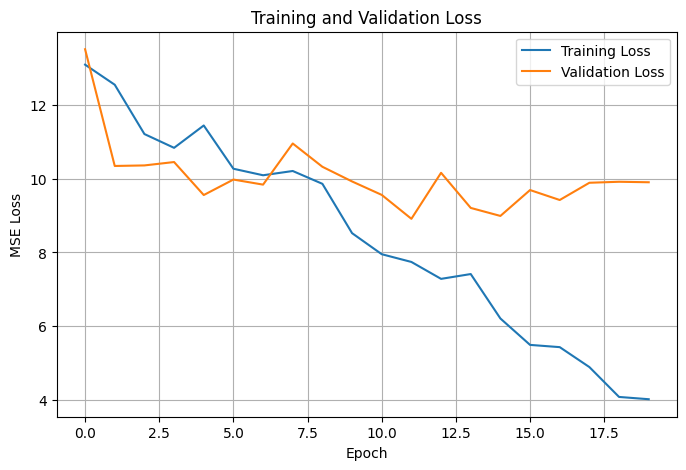

In [48]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

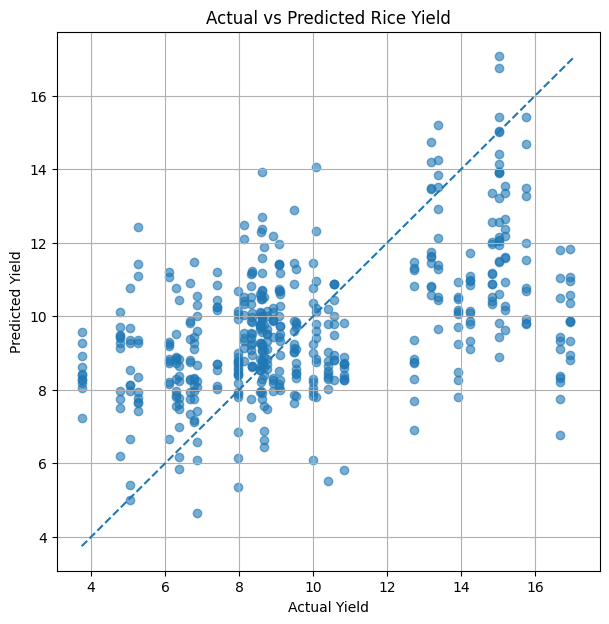

In [49]:
plt.figure(figsize=(7, 7))

plt.scatter(
    val_actuals,
    val_predictions,
    alpha=0.6
)

min_value = min(val_actuals.min(), val_predictions.min())
max_value = max(val_actuals.max(), val_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Rice Yield")

plt.grid(True)
plt.show()

In [50]:
MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "rice_yield_cnn.pth"

torch.save(
    model.state_dict(),
    model_path
)

print(f"Model saved at: {model_path}")

Model saved at: /kaggle/working/PaddyVision-AI/models/rice_yield_cnn.pth


In [51]:
print("Rice Yield CNN")
print("==============")

print(f"Train RMSE: {train_rmse:.4f}")
print(f"Train MAE : {train_mae:.4f}")
print(f"Train R²  : {train_r2:.4f}")

print()

print(f"Val RMSE  : {val_rmse:.4f}")
print(f"Val MAE   : {val_mae:.4f}")
print(f"Val R²    : {val_r2:.4f}")

print()

print(f"Model saved: {model_path}")

Rice Yield CNN
Train RMSE: 2.3909
Train MAE : 1.8261
Train R²  : 0.5177

Val RMSE  : 2.9858
Val MAE   : 2.3421
Val R²    : 0.2353

Model saved: /kaggle/working/PaddyVision-AI/models/rice_yield_cnn.pth


In [52]:
test_samples = []

for date_dir in sorted(TEST_DIR.iterdir()):

    if not date_dir.is_dir():
        continue

    for plot_dir in date_dir.iterdir():

        if not plot_dir.is_dir():
            continue

        if not all(
            (plot_dir / f"{band}.tiff").exists()
            for band in required_bands
        ):
            continue

        test_samples.append({
            "Date": date_dir.name,
            "Year": 2022,
            "Plot_Number": plot_dir.name
        })

test_samples_df = pd.DataFrame(test_samples)

test_samples_df["Plot_Number"] = (
    test_samples_df["Plot_Number"].astype(str)
)

print("Test image samples:", len(test_samples_df))

Test image samples: 2160


In [53]:
test_samples_df = test_samples_df.merge(
    agronomic_df[
        ["Year", "Plot_Number", "Yield", "Replicate"]
    ],
    on=["Year", "Plot_Number"],
    how="left"
)

print("Total test samples:", len(test_samples_df))
print("Samples with yield:", test_samples_df["Yield"].notna().sum())
print("Samples without yield:", test_samples_df["Yield"].isna().sum())

Total test samples: 2160
Samples with yield: 1824
Samples without yield: 336


In [54]:
test_labeled = test_samples_df[
    test_samples_df["Yield"].notna()
].copy()

print("Final test samples:", len(test_labeled))

Final test samples: 1824


In [55]:
test_dataset = RiceYieldDataset(
    test_labeled,
    TEST_DIR
)

print("Test dataset size:", len(test_dataset))

Test dataset size: 1824


In [56]:
test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Test DataLoader ready!")

Test DataLoader ready!


In [57]:
test_images, test_targets = next(iter(test_loader))

print("Test images:", test_images.shape)
print("Test targets:", test_targets.shape)

Test images: torch.Size([16, 5, 64, 64])
Test targets: torch.Size([16])


In [58]:
test_rmse, test_mae, test_r2, test_actuals, test_predictions = evaluate_model(
    model,
    test_loader,
    device
)

print("Final Test Results")
print("===================")

print(f"RMSE: {test_rmse:.4f}")
print(f"MAE : {test_mae:.4f}")
print(f"R²  : {test_r2:.4f}")

Final Test Results
RMSE: 3.9638
MAE : 3.2817
R²  : -0.0043


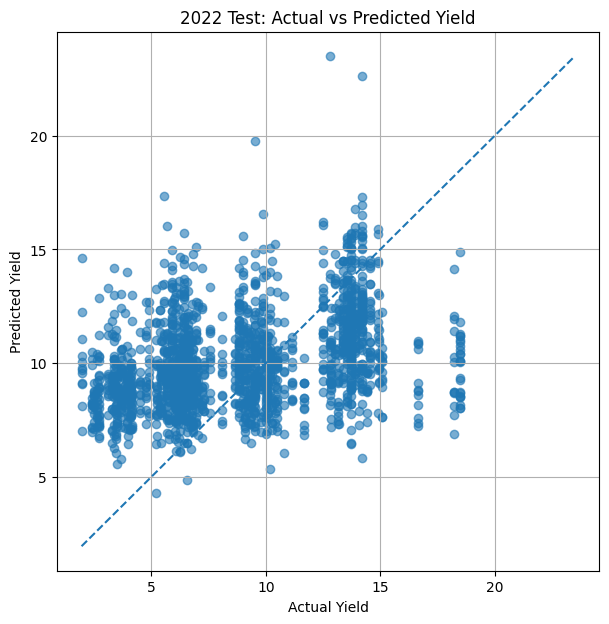

In [59]:
plt.figure(figsize=(7, 7))

plt.scatter(
    test_actuals,
    test_predictions,
    alpha=0.6
)

min_value = min(
    test_actuals.min(),
    test_predictions.min()
)

max_value = max(
    test_actuals.max(),
    test_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("2022 Test: Actual vs Predicted Yield")

plt.grid(True)

plt.show()

In [60]:
results = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "RMSE": [
        train_rmse,
        val_rmse,
        test_rmse
    ],
    "MAE": [
        train_mae,
        val_mae,
        test_mae
    ],
    "R2": [
        train_r2,
        val_r2,
        test_r2
    ]
})

print(results)

      Dataset      RMSE       MAE        R2
0       Train  2.390927  1.826101  0.517669
1  Validation  2.985757  2.342101  0.235275
2        Test  3.963769  3.281669 -0.004266


In [61]:
results_path = PROJECT_ROOT / "outputs" / "rice_yield_results.csv"

results_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

results.to_csv(
    results_path,
    index=False
)

print(f"Results saved at: {results_path}")

Results saved at: /kaggle/working/PaddyVision-AI/outputs/rice_yield_results.csv
